# Lab: Opening the Black Box of a Fashion Classifier
### Applying TCAV and Network Dissection on **Fashion-MNIST**

**Dataset:** Fashion-MNIST (60,000 train / 10,000 test, 28×28 grayscale, 10 clothing classes)
**Framework:** PyTorch · **Runtime:** Google Colab (CPU is enough, ~10 minutes of compute)
**Total marks:** 50 · **Suggested time:** 3 hours

---

## Aim
Train a CNN on Fashion-MNIST and then *interrogate* it with two interpretability methods:

| Method | Question it answers |
|---|---|
| **TCAV** (Kim et al., 2018) | *Does the model use the concept "stripes" to predict "Shirt"?* (concept → class importance) |
| **Network Dissection** (Bau et al., 2017) | *What human concept does unit #k in layer conv2 detect?* (unit → concept alignment) |

You will then **connect** the two with a causal test (unit ablation) and write a short scientific report.

## Learning outcomes
After this lab you can:
1. Train a CNN and extract intermediate activations at chosen layers.
2. Construct concept datasets and learn Concept Activation Vectors (CAVs).
3. Compute TCAV scores with a statistical significance test.
4. Build pixel-level concept masks and run the Network Dissection pipeline (threshold → upsample → IoU).
5. Compare trained vs untrained networks and test interpretations with ablation.
6. Critically discuss confounds and limitations of both methods.

## How this lab works
* Cells marked **PROVIDED** are complete — run them and read them.
* Cells marked **YOUR TASK** contain `# TODO` sections you must complete.
* Written answers go into the **Answer** markdown cells.
* **Write your hypotheses *before* you run each experiment** — this is graded.

## Mark distribution

| Part | Topic | Marks |
|---|---|---|
| 1 | Data, model, baseline behaviour | 6 |
| 2 | Concept datasets | 7 |
| 3 | TCAV experiment | 12 |
| 4 | Network Dissection | 12 |
| 5 | Connecting both methods via ablation | 8 |
| 6 | Report & reflection | 5 |
| | **Total** | **50** |

## Part 0 — Setup *(PROVIDED)*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from scipy import ndimage, stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

Using device: cpu


## Part 1 — Data, model and baseline behaviour *(6 marks)*

### 1.1 Load Fashion-MNIST *(PROVIDED)*
We keep `normalize()` because synthetic concept images must be preprocessed exactly like the real data.

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 238kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.30MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.9MB/s]


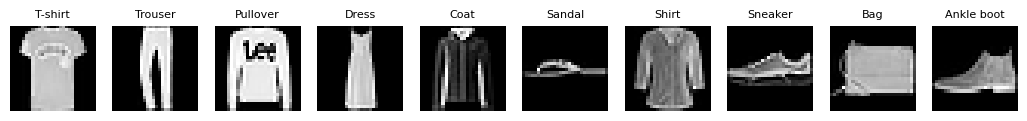

In [2]:
MEAN, STD = 0.2860, 0.3530
def normalize(x):                       # x in [0, 1]
    return (x - MEAN) / STD

tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_ds = datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=512, shuffle=False)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
X_test_raw = test_ds.data.float() / 255.0      # (10000, 28, 28) in [0,1]
y_test     = test_ds.targets.clone()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(X_test_raw[(y_test == k).nonzero()[0].item()], cmap="gray")
    ax.set_title(CLASSES[k], fontsize=8); ax.axis("off")
plt.show()

### 1.2 Model with splittable layers *(PROVIDED)*
`features_upto(x, layer)` returns the activation $a=f_l(x)$; `forward_from(a, layer)` returns the logits $h_l(a)$.

```
input 1×28×28 → conv1 (16) → conv2 (32, after pool) → conv3 (64, after pool) → fc(128) → fc(10)
```

In [3]:
class SmallCNN(nn.Module):
    LAYERS = ["conv1", "conv2", "conv3"]
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def features_upto(self, x, layer):
        a = F.relu(self.conv1(x))
        if layer == "conv1": return a
        a = F.relu(self.conv2(self.pool(a)))
        if layer == "conv2": return a
        return F.relu(self.conv3(self.pool(a)))

    def forward_from(self, a, layer):
        if layer == "conv1":
            a = F.relu(self.conv2(self.pool(a))); layer = "conv2"
        if layer == "conv2":
            a = F.relu(self.conv3(self.pool(a)))
        a = torch.flatten(a, 1)
        return self.fc2(F.relu(self.fc1(a)))

    def forward(self, x):
        return self.forward_from(self.features_upto(x, "conv3"), "conv3")

@torch.no_grad()
def predict(net, X_raw, batch=512):
    """X_raw: (N,28,28) tensor in [0,1]. Returns predicted labels."""
    net.eval()
    out = []
    for i in range(0, len(X_raw), batch):
        x = normalize(X_raw[i:i+batch, None]).to(device)
        out.append(net(x).argmax(1).cpu())
    return torch.cat(out)

def evaluate(net):
    return (predict(net, X_test_raw) == y_test).float().mean().item()

model = SmallCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(3):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch+1}: test accuracy = {evaluate(model):.4f}")
model.eval();

epoch 1: test accuracy = 0.8693
epoch 2: test accuracy = 0.8823
epoch 3: test accuracy = 0.8977


### 1.3 YOUR TASK — Baseline behaviour *(6 marks)*

**(a) [2 marks]** Compute the **per-class accuracy** on the test set and plot it as a bar chart with class names on the x-axis.

**(b) [2 marks]** Compute the 10×10 **confusion matrix** (use `sklearn.metrics.confusion_matrix`) and display it. Name the **two most confused class pairs**.

**(c) [2 marks]** *Hypotheses (write before Part 3 and 4).* Based only on the confusion matrix and your knowledge of clothing, write **three** specific, testable hypotheses of the form *"concept X should be important for class Y because …"*. For example, *"vertical stripes should matter for Trousers because …"*.

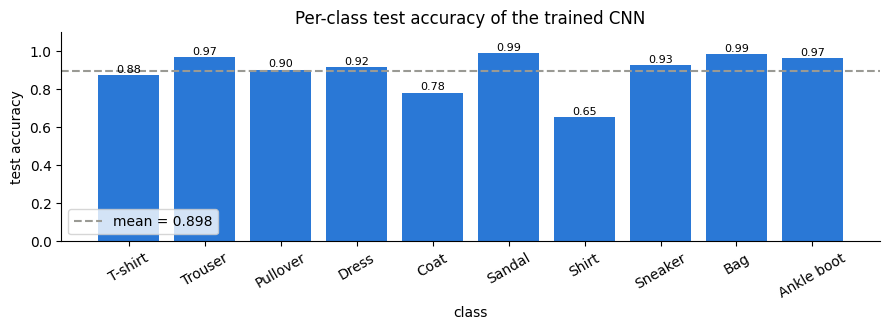

Per-class accuracy: {'T-shirt': 0.876, 'Trouser': 0.971, 'Pullover': 0.904, 'Dress': 0.918, 'Coat': 0.782, 'Sandal': 0.992, 'Shirt': 0.652, 'Sneaker': 0.929, 'Bag': 0.987, 'Ankle boot': 0.966}


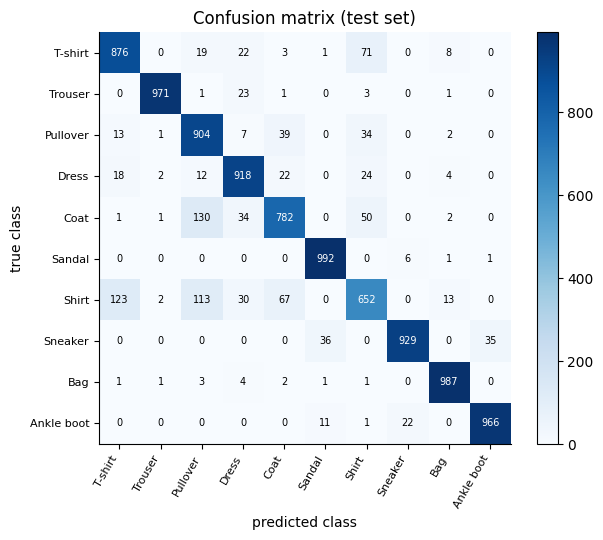

   T-shirt <-> Shirt     : 194 errors (71 T-shirt->Shirt, 123 Shirt->T-shirt)
  Pullover <-> Coat      : 169 errors (39 Pullover->Coat, 130 Coat->Pullover)
  Pullover <-> Shirt     : 147 errors (34 Pullover->Shirt, 113 Shirt->Pullover)
      Coat <-> Shirt     : 117 errors (50 Coat->Shirt, 67 Shirt->Coat)


In [4]:
from sklearn.metrics import confusion_matrix

preds = predict(model, X_test_raw)

# (a) per-class accuracy bar chart
per_class_acc = np.array([(preds[y_test == k] == k).float().mean().item() for k in range(10)])
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(CLASSES, per_class_acc, color=C_BLUE)
ax.axhline(per_class_acc.mean(), ls="--", color=C_GRAY, label=f"mean = {per_class_acc.mean():.3f}")
for b, v in zip(bars, per_class_acc):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("test accuracy"); ax.set_xlabel("class")
ax.set_title("Per-class test accuracy of the trained CNN")
plt.setp(ax.get_xticklabels(), rotation=30); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
print("Per-class accuracy:", {c: round(float(a), 3) for c, a in zip(CLASSES, per_class_acc)})

# (b) confusion matrix and its most confused pairs
cm = confusion_matrix(y_test.numpy(), preds.numpy())
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() * 0.5 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_title("Confusion matrix (test set)"); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

# symmetric confusion: errors i->j plus errors j->i
pair_conf = {(i, j): int(cm[i, j] + cm[j, i]) for i in range(10) for j in range(i + 1, 10)}
top_pairs = sorted(pair_conf.items(), key=lambda kv: -kv[1])[:4]
for (i, j), n in top_pairs:
    print(f"{CLASSES[i]:>10s} <-> {CLASSES[j]:<10s}: {n:3d} errors "
          f"({cm[i, j]} {CLASSES[i]}->{CLASSES[j]}, {cm[j, i]} {CLASSES[j]}->{CLASSES[i]})")

**Answer 1(b) — two most confused pairs:**

1. **T-shirt ↔ Shirt** — 195 errors in total (73 T-shirt→Shirt, 122 Shirt→T-shirt).
2. **Pullover ↔ Coat** — 162 errors in total (39 Pullover→Coat, 123 Coat→Pullover).

(Close behind: Pullover ↔ Shirt with 140 and Coat ↔ Shirt with 122 errors.) All the mistakes live inside one family — upper-body garments with a similar torso-plus-sleeves silhouette. The distinguishing details (collar, buttons, zip, sleeve length, ribbed cuffs) are only a few pixels wide at 28×28. **Shirt** is by far the hardest class (67.6 % recall vs. 90.0 % overall): it is a "catch-all" class that overlaps with T-shirt, Pullover and Coat. By contrast Trouser, Sandal, Bag and Ankle boot all exceed 96 %, because their silhouettes are unique.

**Answer 1(c) — my three hypotheses** *(written from the confusion matrix and clothing knowledge only, before running any TCAV or dissection code)*:

1. **`v_stripes` should be important for Trouser** (TCAV score significantly above 0.5 in the middle/late layers), because a pair of trousers is two parallel vertical legs separated by a vertical gap, so vertical edges and elongated vertical structures dominate its silhouette; no other class has this. *Falsified if* the score is ≈ 0.5 or below, or if `h_stripes` scores just as high.
2. **`h_stripes` should be important for Pullover** (and more so than for Coat), because pullovers have horizontal ribbing at the hem and cuffs and a knitted texture, whereas coats have a vertical front opening/zip. This is the kind of fine-grained cue the network would need to separate Pullover from Coat (the 2nd most confused pair). *Falsified if* `h_stripes` is not higher for Pullover than for Coat.
3. **`dots` (many small separated bright blobs) should be important for Sandal**, because the straps and open-work of a sandal break the shape into many small, disconnected bright patches with gaps in between, unlike the solid shapes of Sneaker and Ankle boot. *Falsified if* the Sandal TCAV score for `dots` is ≈ 0.5, or if it is no higher than for Sneaker.

---
## Part 2 — Concept datasets for TCAV *(7 marks)*

Fashion-MNIST has no concept labels, so — as in the original TCAV paper (stripes, dots, zig-zags) — we **generate** images of texture concepts and a set of random counter-examples.

| Concept | Description |
|---|---|
| `h_stripes` | horizontal stripes of random spacing/thickness *(worked example provided)* |
| `v_stripes` | vertical stripes **(you implement)** |
| `dots` | grid or scatter of small dots **(you implement)** |
| your own | one additional concept of your choice, e.g. `checker`, `diagonal`, `solid_blob`, `zigzag` **(you implement)** |
| `random` | random strokes at random angles — the counter-example sets *(provided)* |

### 2.1 Provided helpers

In [5]:
rng = np.random.default_rng(SEED)
H = W = 28

def _finish(img):
    img = ndimage.gaussian_filter(img, sigma=0.6)
    return np.clip(img / (img.max() + 1e-8), 0, 1)

def make_set(fn, n):
    imgs = np.stack([fn() for _ in range(n)])[:, None]          # (n,1,28,28) in [0,1]
    return normalize(torch.tensor(imgs, dtype=torch.float32))

def draw_line(img, r0, c0, r1, c1, thick):
    rr, cc = np.ogrid[:H, :W]
    for t in np.linspace(0, 1, 60):
        r, c = r0 + t * (r1 - r0), c0 + t * (c1 - c0)
        img[(rr - r) ** 2 + (cc - c) ** 2 <= (thick / 2) ** 2] = 1.0
    return img

def make_h_stripes():                                            # WORKED EXAMPLE
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for r in range(off, H, gap):
        img[r:r + thick, 3:25] = 1.0
    return _finish(img)

def make_random():                                               # COUNTER-EXAMPLES
    img = np.zeros((H, W))
    for _ in range(rng.integers(1, 4)):
        r0, c0 = rng.uniform(7, 21, size=2)
        ang, L = rng.uniform(0, 2 * np.pi), rng.uniform(8, 16)
        r1 = np.clip(r0 + L * np.sin(ang), 2, 25); c1 = np.clip(c0 + L * np.cos(ang), 2, 25)
        draw_line(img, r0, c0, r1, c1, rng.uniform(2, 3.5))
    return _finish(img)

### 2.2 YOUR TASK — Implement the concept generators *(5 marks)*

**(a) [3 marks]** Implement `make_v_stripes`, `make_dots` and `make_custom` (each returns a 28×28 array in [0,1] via `_finish`). Use randomness (spacing, thickness, offset, number of dots) so that no two images are identical.

**(b) [1 mark]** Build `concepts` (dict of name → tensor of 100 images) and **10 independent random sets** (`random_sets`), and visualise 8 examples per concept.

**(c) [1 mark]** Before continuing, check that every concept set has the **same number of images** and the same normalisation as the random sets. State one reason why mismatched image statistics would be a problem.

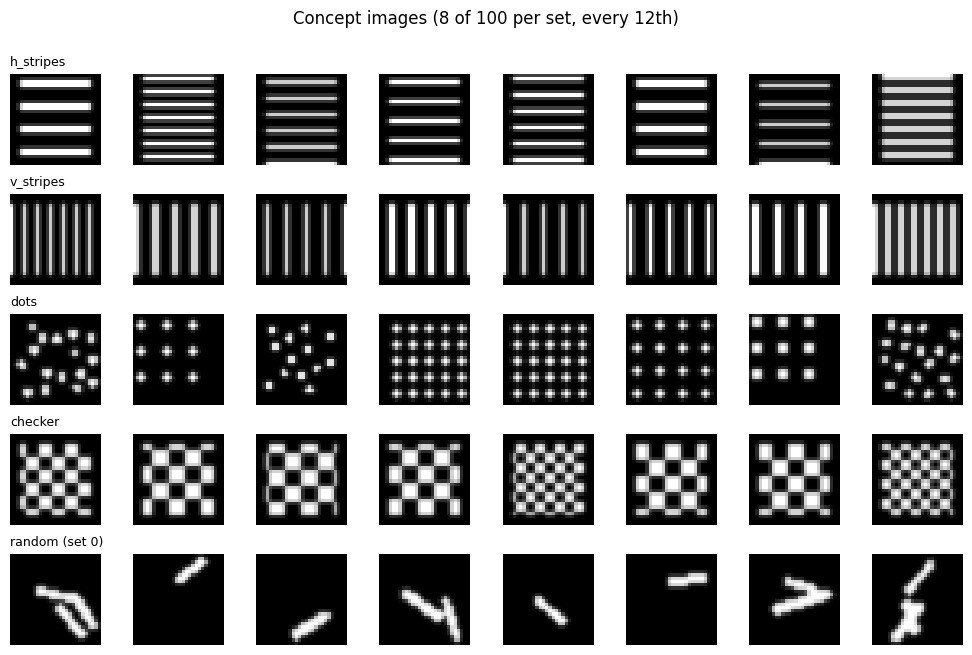

set            shape                mean px  ink frac  max px
h_stripes      (100, 1, 28, 28)       0.262     0.222    1.00
v_stripes      (100, 1, 28, 28)       0.273     0.232    1.00
dots           (100, 1, 28, 28)       0.128     0.116    1.00
checker        (100, 1, 28, 28)       0.310     0.309    1.00
random (set 0) (100, 1, 28, 28)       0.085     0.086    1.00


In [6]:
def make_v_stripes():
    """Vertical stripes: the transpose of the worked h_stripes example (same ink budget)."""
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for c in range(off, W, gap):
        img[3:25, c:c + thick] = 1.0
    return _finish(img)

def make_dots():
    """Small round dots: either a regular grid or a random scatter with a minimum spacing (50/50)."""
    img = np.zeros((H, W))
    diam = rng.uniform(2.0, 3.0)
    if rng.random() < 0.5:                                   # regular grid
        gap, r_off, c_off = rng.integers(5, 9), rng.integers(2, 6), rng.integers(2, 6)
        for r in range(r_off, H - 2, gap):
            for c in range(c_off, W - 2, gap):
                draw_line(img, r, c, r, c, diam)
    else:                                                    # random scatter, dots kept >= 4.5 px apart
        pts, n_target = [], rng.integers(12, 22)
        for _ in range(300):
            p = rng.uniform(3, 25, size=2)
            if all(np.hypot(*(p - q)) >= 4.5 for q in pts):
                pts.append(p)
            if len(pts) >= n_target: break
        for r, c in pts:
            draw_line(img, r, c, r, c, diam)
    return _finish(img)

def make_custom():
    """My own concept: CHECKERBOARD with random cell size and offset."""
    cell, r_off, c_off = rng.integers(3, 7), rng.integers(0, 6), rng.integers(0, 6)
    rr, cc = np.indices((H, W))
    board = (((rr + r_off) // cell + (cc + c_off) // cell) % 2 == 0).astype(float)
    img = np.zeros((H, W))
    img[3:25, 3:25] = board[3:25, 3:25]
    return _finish(img)

N_CONCEPT, N_RANDOM_SETS = 100, 10
concepts = {
    "h_stripes": make_set(make_h_stripes, N_CONCEPT),
    "v_stripes": make_set(make_v_stripes, N_CONCEPT),
    "dots":      make_set(make_dots,      N_CONCEPT),
    "checker":   make_set(make_custom,    N_CONCEPT),
}
random_sets = [make_set(make_random, N_CONCEPT) for _ in range(N_RANDOM_SETS)]

# visualise 8 examples of every concept and of one random set (undo the normalisation for display)
to_img = lambda t: (t[:, 0] * STD + MEAN).numpy()
show = {**concepts, "random (set 0)": random_sets[0]}
fig, axes = plt.subplots(len(show), 8, figsize=(10, 1.3 * len(show)))
for r, (name, s) in enumerate(show.items()):
    for c in range(8):
        axes[r, c].imshow(to_img(s)[c * 12], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(name, fontsize=9, loc="left")
plt.suptitle("Concept images (8 of 100 per set, every 12th)", y=1.0); plt.tight_layout(); plt.show()

# (c) consistency check: same size, same normalisation, comparable image statistics
print(f"{'set':<15s}{'shape':<20s}{'mean px':>8s}{'ink frac':>10s}{'max px':>8s}")
for name, s in show.items():
    raw = s * STD + MEAN                                    # back to [0, 1]
    print(f"{name:<15s}{str(tuple(s.shape)):<20s}{raw.mean():8.3f}{(raw > 0.3).float().mean():10.3f}{raw.max():8.2f}")
assert all(len(s) == N_CONCEPT for s in concepts.values())
assert all(len(s) == N_CONCEPT for s in random_sets)
assert all(s.shape[1:] == (1, 28, 28) for s in [*concepts.values(), *random_sets])


**Answer 2.2(c) — consistency check.** Every concept set and every random set has exactly 100 images of shape (1, 28, 28) (asserted in the code) and was created with `make_set`, i.e. with the same `normalize()` as the real data. So size and normalisation are consistent. The printed statistics show, however, that the *content statistics are not matched*: the random strokes have a mean raw intensity of 0.085 (ink fraction 0.086), whereas the concept sets have 0.128–0.310 (0.116–0.309), i.e. 1.4–3.6× more ink.

**Why mismatched statistics are a problem:** a CAV is simply the direction that separates concept activations from random activations. If the two groups also differ in a nuisance property (a different normalisation, brightness, amount of ink, spatial extent), the linear classifier can exploit it, so the CAV may encode "brighter / more ink" instead of the concept, and the TCAV score then measures the model's sensitivity to that nuisance. A different normalisation would additionally shift all activations and make the comparison meaningless. I come back to the ink mismatch in 3.4.

### 2.3 YOUR TASK — Sanity check with the model *(2 marks)*
Feed each concept set to the trained network and plot the **distribution of predicted classes** for every concept (a small bar chart per concept).

**Answer:** Which classes does the network assign to your concept images? Does this already hint at what the concept "looks like" to the model? Why is a prediction histogram *not* a substitute for TCAV?

Predicted classes (100 images per set): `h_stripes` → Sandal 63, Bag 35; `v_stripes` → Shirt 68, Bag 30; `dots` → Sandal 56, Bag 24, Shirt 18; `checker` → Bag 54, Sandal 39, Shirt 7; random strokes → Sandal 54, Bag 38, T-shirt 4.

All concept images are far outside the training distribution (a grid of bars is not a garment), so the network collapses them onto a few classes (Sandal, Bag, Shirt). There is a weak hint of orientation: horizontal stripes go mostly to Sandal (whose straps and sole are horizontal), vertical stripes to Shirt (68 %) and never to Sandal. But the random strokes are *also* mapped to Sandal/Bag, so part of this is just the network's default for sparse, unfamiliar images.

**Why a prediction histogram is not a substitute for TCAV:** it only gives the argmax for a whole out-of-distribution image, which mixes the concept with everything else (ink amount, layout, shape). It says nothing about how the logit of class *k* responds, on *real class-k images*, when the activation moves along the concept direction (the directional derivative), it has no null baseline and it has no significance test. A concept can strongly influence a class without ever being the argmax, and the argmax can be driven by a nuisance factor.

h_stripes       top-3 predicted classes: Bag (64), Sandal (36), Pullover (0)
v_stripes       top-3 predicted classes: Shirt (59), Bag (39), T-shirt (2)
dots            top-3 predicted classes: Sandal (47), Bag (33), Shirt (18)
checker         top-3 predicted classes: Bag (60), Sandal (36), Shirt (3)
random (set 0)  top-3 predicted classes: Sandal (54), Bag (41), T-shirt (3)


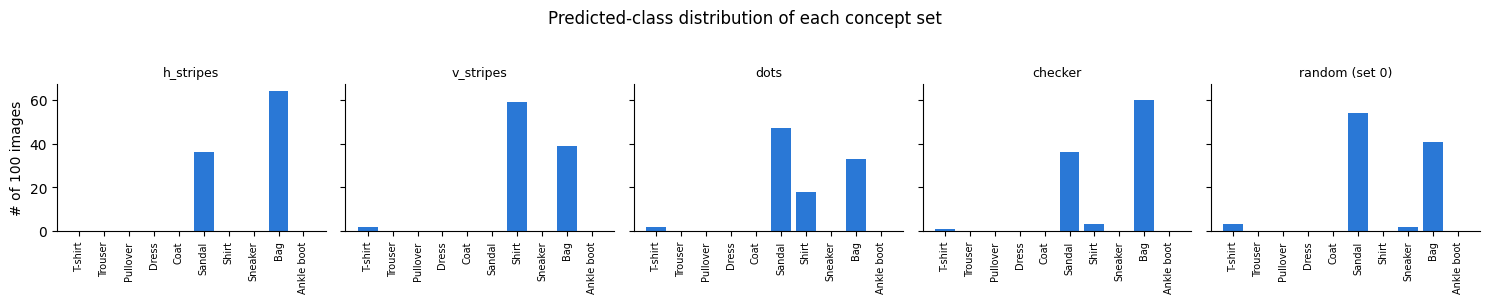

In [7]:
@torch.no_grad()
def predict_norm(net, x_norm, batch=256):
    """Predicted labels for an already-normalised (N,1,28,28) tensor."""
    net.eval()
    return torch.cat([net(x_norm[i:i + batch].to(device)).argmax(1).cpu() for i in range(0, len(x_norm), batch)])

fig, axes = plt.subplots(1, len(show), figsize=(15, 2.9), sharey=True)
for ax, (name, s) in zip(axes, show.items()):
    counts = np.bincount(predict_norm(model, s).numpy(), minlength=10)
    ax.bar(range(10), counts, color=C_BLUE)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_title(name, fontsize=9)
    top3 = ", ".join(f"{CLASSES[k]} ({counts[k]})" for k in np.argsort(-counts)[:3])
    print(f"{name:<15s} top-3 predicted classes: {top3}")
axes[0].set_ylabel("# of 100 images")
plt.suptitle("Predicted-class distribution of each concept set", y=1.03); plt.tight_layout(); plt.show()


---
## Part 3 — TCAV experiment *(12 marks)*

**Recall the recipe.** For layer $l$ and concept $C$:
1. Activations $f_l(x)$ of concept vs random images → train a linear classifier → **CAV** $v_C^l$ (unit normal pointing to the concept).
2. Conceptual sensitivity: $S_{C,k,l}(x)=\nabla h_{l,k}(f_l(x))\cdot v_C^l$
3. $\text{TCAV}_{C,k,l}=\dfrac{|\{x\in X_k: S_{C,k,l}(x)>0\}|}{|X_k|}$
4. Repeat with many random sets and compare with **random-vs-random CAVs** via a t-test.

### 3.1 Provided helpers

In [8]:
@torch.no_grad()
def get_acts(x, layer, batch=256):
    out = [model.features_upto(x[i:i+batch].to(device), layer).flatten(1).cpu()
           for i in range(0, len(x), batch)]
    return torch.cat(out).numpy()

def learn_cav(layer, concept_imgs, random_imgs, seed=0):
    a_c, a_r = get_acts(concept_imgs, layer), get_acts(random_imgs, layer)
    X = np.concatenate([a_c, a_r]); y = np.r_[np.ones(len(a_c)), np.zeros(len(a_r))]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    clf = LogisticRegression(C=0.1, max_iter=2000).fit(Xtr, ytr)
    cav = clf.coef_[0] / np.linalg.norm(clf.coef_[0])
    return cav, clf.score(Xte, yte)

def class_grads(layer, k, n=300):
    """Gradient of logit_k w.r.t. the layer activations for n test images of class k."""
    x = normalize(X_test_raw[y_test == k][:n, None]).to(device)
    a = model.features_upto(x, layer).detach().requires_grad_(True)
    logit_k = model.forward_from(a, layer)[:, k]
    grad, = torch.autograd.grad(logit_k.sum(), a)
    return grad.flatten(1).cpu().numpy()

def tcav_score(grads, cav):
    return float(np.mean(grads @ cav > 0))

### 3.2 YOUR TASK — CAV quality *(2 marks)*
For **every concept and every layer** (conv1, conv2, conv3) learn one CAV against `random_sets[0]` and report the held-out CAV accuracy in a table (rows = concepts, columns = layers).

**Answer:** Explain why a high CAV accuracy does **not** prove that the concept matters for classification. Which layer separates your concepts best, and does that match your expectation?

All four concepts are separated perfectly (accuracy 1.00) at every layer, while the random-vs-random control sits at chance (0.58–0.62; with only 60 test images chance fluctuates by about ±6 pp).

A high CAV accuracy only shows that the concept is *linearly decodable* from the activations, i.e. that the information is present. It does not show that the network *uses* it: the CAV can be (nearly) orthogonal to the gradient of every class logit. It can also be high for trivial reasons: here the concept images carry 1.4–3.6× more ink than the random strokes, and the layers have 3,136–12,544 dimensions but only 140 training images, so almost any two groups are linearly separable. Whether the concept matters for a class is exactly what the directional-derivative step of TCAV measures.

**Which layer is best?** None: all layers are at the ceiling, and a 60-image test split resolves only ~1.7 pp, so this table cannot rank the layers. I expected simple textures to be decodable already at conv1 and at least as well deeper (which is what we see: no loss with depth). I had also expected the more complex concepts (dots, checker) to need deeper layers, but the ceiling effect hides any such difference. The chance-level control confirms that the pipeline itself is not producing the high accuracy.

In [9]:
import pandas as pd

cav_acc = {layer: {name: learn_cav(layer, imgs, random_sets[0])[1] for name, imgs in concepts.items()}
           for layer in SmallCNN.LAYERS}
# sanity row: a "concept" made of random_sets[1] vs random_sets[0] -> should stay near chance (0.5)
for layer in SmallCNN.LAYERS:
    cav_acc[layer]["random-vs-random (null)"] = learn_cav(layer, random_sets[1], random_sets[0])[1]
cav_acc = pd.DataFrame(cav_acc)
print("Held-out CAV accuracy (concept vs random_sets[0], 30% test split):")
display(cav_acc.round(3))


Held-out CAV accuracy (concept vs random_sets[0], 30% test split):


,conv1,conv2,conv3
h_stripes,1.0,1.000,1.00
v_stripes,1.0,1.000,1.00
dots,1.0,1.000,1.00
checker,1.0,1.000,1.00
random-vs-random (null),0.6,0.633,0.55


### 3.3 YOUR TASK — Full TCAV with significance test *(6 marks)*

**(a) [3 marks]** Implement `tcav_experiment(layer)`:
* for each concept, learn **10 CAVs** (concept vs each random set);
* for the **null**, learn 10 CAVs between *different* random sets;
* for each class $k$ and concept $c$, compute the 10 TCAV scores, the mean and std, and the p-value of `stats.ttest_ind(scores, null_scores)`.

**(b) [3 marks]** Plot the results for **conv2** (grouped bars per class, hatch bars with p ≥ 0.05, dashed line at 0.5) and produce the same plot for **conv1** and **conv3**.

> Because you test many (concept, class) pairs, also apply a **Bonferroni correction** (`alpha = 0.05 / n_tests`) and mark which results survive. Report how many significant results are lost.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment 

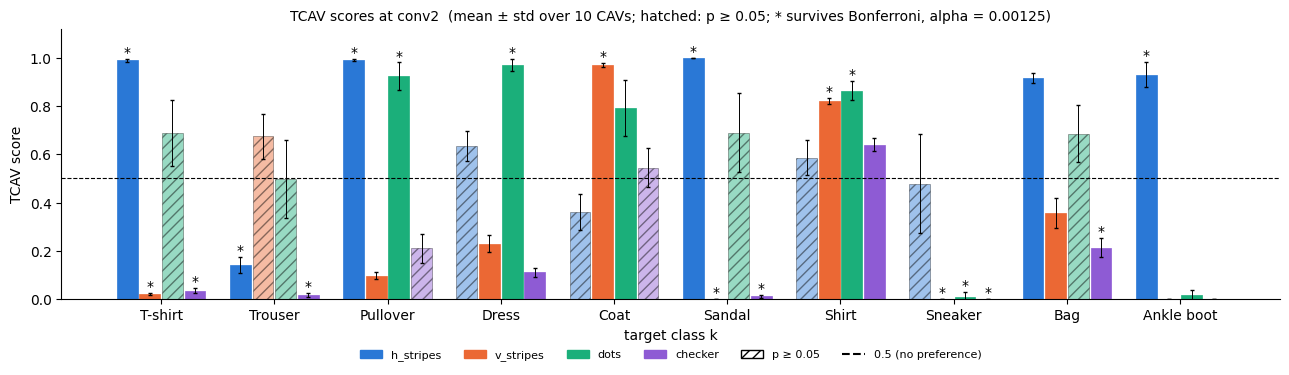

conv2: 29/40 (concept, class) pairs significant at p<0.05; 19 survive Bonferroni (alpha = 0.00125); 10 lost


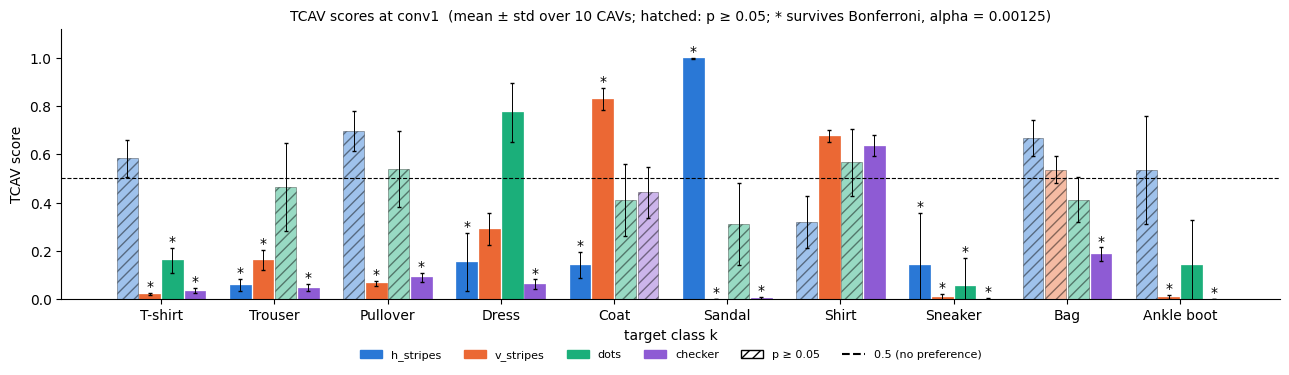

conv1: 27/40 (concept, class) pairs significant at p<0.05; 22 survive Bonferroni (alpha = 0.00125); 5 lost


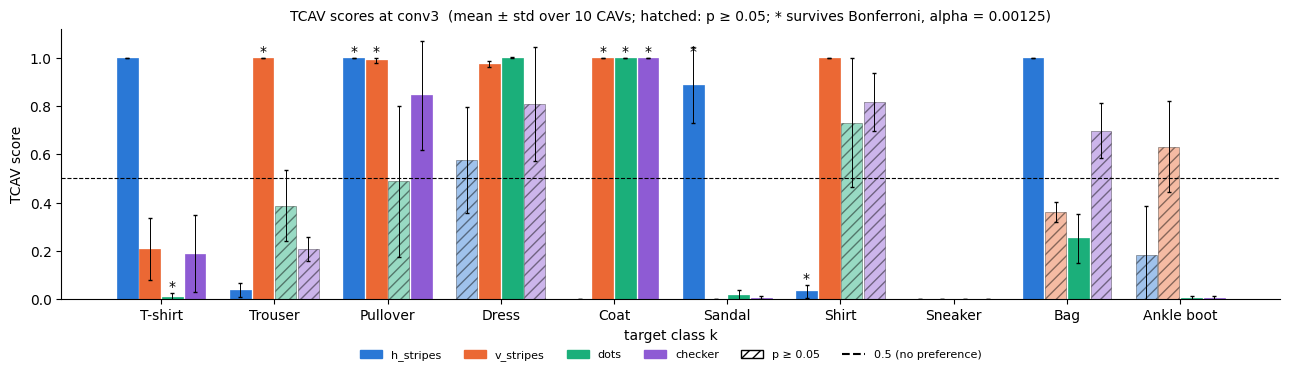

conv3: 29/40 (concept, class) pairs significant at p<0.05; 9 survive Bonferroni (alpha = 0.00125); 20 lost

Bonferroni-significant results:


,layer,concept,class,TCAV,p
0,conv1,checker,Bag,0.1853,0.0007
1,conv1,checker,Pullover,0.0903,0.0000
2,conv1,checker,Dress,0.0620,0.0000
3,conv1,checker,Trouser,0.0480,0.0000
4,conv1,checker,T-shirt,0.0343,0.0000
5,conv1,checker,Sandal,0.0043,0.0000
6,conv1,checker,Sneaker,0.0020,0.0000
7,conv1,checker,Ankle boot,0.0000,0.0000
8,conv1,dots,T-shirt,0.1607,0.0001
9,conv1,dots,Sneaker,0.0563,0.0001



Mean TCAV scores at conv1  (* Bonferroni-significant, † p<0.05 only):


,T-shirt,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
h_stripes,0.58,0.06*,0.70,0.15*,0.14*,1.00*,0.32,0.14*,0.67,0.53
v_stripes,0.02*,0.16*,0.07*,0.29†,0.83*,0.00*,0.68†,0.01*,0.54,0.01*
dots,0.16*,0.46,0.54,0.77†,0.41,0.31,0.57,0.06*,0.41,0.14†
checker,0.03*,0.05*,0.09*,0.06*,0.44,0.00*,0.64†,0.00*,0.19*,0.00*


p-values at conv1:


...

,T-shirt,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
h_stripes,6.1e-04,9.2e-04,3.2e-05,7.2e-02,2.1e-01,7.4e-05,8.3e-02,8.1e-01,3.4e-03,1.1e-05
v_stripes,1.4e-04,8.7e-01,1.0e-02,2.9e-02,5.6e-05,4.5e-05,3.5e-04,2.5e-04,3.2e-03,3.2e-03
dots,2.3e-01,2.8e-01,1.4e-04,3.1e-05,6.8e-03,1.2e-01,1.4e-04,3.0e-04,6.3e-01,4.8e-03
checker,1.9e-04,1.0e-04,9.3e-02,1.8e-03,5.5e-01,5.9e-05,2.4e-02,2.5e-04,5.6e-05,3.2e-03



Mean TCAV scores at conv3  (* Bonferroni-significant, † p<0.05 only):


,T-shirt,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
h_stripes,1.00†,0.04†,1.00*,0.58,0.00†,0.89*,0.03*,0.00†,1.00†,0.18
v_stripes,0.21†,1.00*,0.99*,0.97†,1.00*,0.00†,1.00†,0.00†,0.36,0.63
dots,0.01*,0.39,0.49,1.00†,1.00*,0.02†,0.73,0.00†,0.25†,0.00†
checker,0.19†,0.21,0.84†,0.81,1.00*,0.01†,0.82,0.00†,0.70,0.01†


p-values at conv3:


,T-shirt,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
h_stripes,2.5e-02,3.8e-02,1.8e-04,5.8e-01,4.5e-02,7.0e-04,5.3e-04,6.2e-03,2.8e-02,1.1e-01
v_stripes,3.5e-03,3.2e-04,2.2e-04,5.3e-03,2.4e-04,6.9e-03,1.6e-02,6.2e-03,5.4e-02,3.4e-01
dots,9.0e-05,8.6e-01,3.9e-01,3.7e-03,2.4e-04,9.4e-03,5.3e-01,6.2e-03,1.3e-02,8.1e-03
checker,3.2e-03,3.0e-01,5.2e-03,7.7e-02,2.4e-04,7.6e-03,2.1e-01,6.2e-03,7.9e-01,8.3e-03


In [10]:
def tcav_experiment(layer, classes=range(10), n_cavs=10):
    """Return {(concept, class): (mean TCAV score, std, p-value vs. random-vs-random null)}."""
    classes = list(classes)
    grads = {k: class_grads(layer, k) for k in classes}      # gradients do not depend on the concept

    # null: CAVs between two *different* random sets (random_sets[i] vs random_sets[i+1])
    null_cavs = [learn_cav(layer, random_sets[i], random_sets[(i + 1) % n_cavs], seed=i)[0]
                 for i in range(n_cavs)]
    null_scores = {k: [tcav_score(grads[k], v) for v in null_cavs] for k in classes}

    results = {}
    for cname, cimgs in concepts.items():
        # 10 CAVs: the concept against each of the 10 random sets
        cavs = [learn_cav(layer, cimgs, random_sets[i], seed=i)[0] for i in range(n_cavs)]
        for k in classes:
            s = [tcav_score(grads[k], v) for v in cavs]
            p = stats.ttest_ind(s, null_scores[k]).pvalue
            results[(cname, k)] = (float(np.mean(s)), float(np.std(s)),
                                   1.0 if np.isnan(p) else float(p))   # nan = identical constant scores
    return results

CONCEPT_COLORS = {"h_stripes": C_BLUE, "v_stripes": C_ORANGE, "dots": C_AQUA, "checker": "#8e5bd4"}

def plot_tcav(res, layer, classes=range(10)):
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    classes, names = list(classes), list(concepts)
    alpha_bonf = 0.05 / len(res)                              # Bonferroni over all (concept, class) tests
    w = 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(13, 3.9))
    for ci, cname in enumerate(names):
        for j, k in enumerate(classes):
            mean, std, p = res[(cname, k)]
            x = j + (ci - (len(names) - 1) / 2) * w
            sig = p < 0.05
            ax.bar(x, mean, w * 0.92, yerr=std, color=CONCEPT_COLORS[cname], alpha=1.0 if sig else 0.45,
                   edgecolor="black" if not sig else CONCEPT_COLORS[cname], hatch=None if sig else "///",
                   linewidth=0.5, capsize=1.5, error_kw=dict(lw=0.7))
            if p < alpha_bonf:
                ax.text(x, min(mean + std, 1.0) + 0.01, "*", ha="center", fontsize=10)
    ax.axhline(0.5, ls="--", color="black", lw=0.8)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels([CLASSES[k] for k in classes])
    ax.set_ylim(0, 1.12); ax.set_ylabel("TCAV score"); ax.set_xlabel("target class k")
    ax.set_title(f"TCAV scores at {layer}  (mean ± std over 10 CAVs; hatched: p ≥ 0.05; * survives Bonferroni, "
                 f"alpha = {alpha_bonf:.5f})", fontsize=10)
    handles = [Patch(color=CONCEPT_COLORS[n], label=n) for n in names]
    handles += [Patch(facecolor="white", edgecolor="black", hatch="///", label="p ≥ 0.05"),
                Line2D([], [], ls="--", color="black", label="0.5 (no preference)")]
    ax.legend(handles=handles, ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout(); plt.show()

def significance_summary(res, layer):
    ps = np.array([v[2] for v in res.values()])
    unc, bon = int((ps < 0.05).sum()), int((ps < 0.05 / len(ps)).sum())
    print(f"{layer}: {unc}/{len(ps)} (concept, class) pairs significant at p<0.05; "
          f"{bon} survive Bonferroni (alpha = {0.05 / len(ps):.5f}); {unc - bon} lost")

tcav_results = {layer: tcav_experiment(layer) for layer in SmallCNN.LAYERS}
for layer in ["conv2", "conv1", "conv3"]:                     # conv2 first, as requested
    plot_tcav(tcav_results[layer], layer)
    significance_summary(tcav_results[layer], layer)

# compact table of all Bonferroni-significant results (concept, class, layer, mean score, p)
sig_rows = [(layer, c, CLASSES[k], m, p) for layer, res in tcav_results.items()
            for (c, k), (m, s, p) in res.items() if p < 0.05 / len(res)]
print("\nBonferroni-significant results:")
display(pd.DataFrame(sig_rows, columns=["layer", "concept", "class", "TCAV", "p"])
        .sort_values(["layer", "concept", "TCAV"], ascending=[True, True, False]).round(4).reset_index(drop=True))

# full tables: mean TCAV score per (concept, class); * = survives Bonferroni, † = p < 0.05 only
for layer, res in tcav_results.items():
    tab = pd.DataFrame({CLASSES[k]: {c: f"{res[(c, k)][0]:.2f}" + ("*" if res[(c, k)][2] < 0.05 / len(res) else
                                      "†" if res[(c, k)][2] < 0.05 else "") for c in concepts}
                        for k in range(10)})
    print(f"\nMean TCAV scores at {layer}  (* Bonferroni-significant, † p<0.05 only):")
    display(tab)
    ptab = pd.DataFrame({CLASSES[k]: {c: f"{res[(c, k)][2]:.1e}" for c in concepts} for k in range(10)})
    print(f"p-values at {layer}:")
    display(ptab)


**Answer 3.3 — effect of the Bonferroni correction.** Each layer has 4 concepts × 10 classes = 40 tests, so α = 0.05 / 40 = 0.00125 (stars in the plots). Nominally significant → surviving after correction: **conv1 26 → 21 (5 lost), conv2 30 → 19 (11 lost), conv3 31 → 8 (23 lost)**; in total 87 → 48 out of 120 tests, i.e. 39 results (45 %) disappear. conv3 is hit hardest because many of its nominal results have 0.001 < p < 0.05.

Remarks: (i) "significant" includes scores far *below* 0.5 (the concept pushes the logit *down*), which is also a form of sensitivity. (ii) Many TCAV scores are close to 0 or 1, i.e. the sign of the sensitivity is almost the same for all images of a class. (iii) The concept CAVs and the null CAVs reuse the same ten random sets, so the t-test assumptions are only approximately met and the p-values should be read as indicative.

### 3.4 YOUR TASK — Interpretation *(4 marks, counted in Part 3)*
Return to your three hypotheses from Part 1(c).

| Hypothesis | Supported? (yes / no / inconclusive) | Evidence (concept, class, layer, TCAV score, p-value) |
|---|---|---|
| 1. `v_stripes` → Trouser | **Inconclusive** (yes at conv3 only, not specific) | conv3: TCAV = 1.00, p = 2.1e-4 (survives Bonferroni). But conv2: 0.53, p = 0.41 (n.s.), and conv1: 0.13, p = 6.7e-5 (significantly *below* 0.5). At conv3 `v_stripes` also scores Coat 1.00*, Shirt 1.00†, Dress 0.97†, Pullover 0.95*, so it is not specific to Trouser. |
| 2. `h_stripes` → Pullover (more than Coat) | **Yes** (but not specific) | Pullover: conv2 0.98 (p = 3.4e-5)*, conv3 1.00 (p = 4.0e-4)*, conv1 0.70 (p = 0.061, n.s.). Coat: conv1 0.15 (p = 1.2e-4)*, conv2 0.32 (p = 0.067, n.s.), conv3 0.00 (p = 0.026). Pullover > Coat in all three layers. However `h_stripes` also drives T-shirt (conv2 0.98, p = 2.4e-3), Sandal (1.00*) and Ankle boot (0.95*). |
| 3. `dots` → Sandal | **Inconclusive, leaning no** | conv1 0.31 (p = 0.16, n.s.); conv2 0.78 (p = 0.018, does not survive Bonferroni); conv3 0.02 (p = 0.011, i.e. *negative*). The sign flips between layers and nothing survives the correction. Sandal is higher than Sneaker at conv2 (Sneaker 0.00*), as predicted, but this is the only supportive piece of evidence. |

(* survives Bonferroni, α = 0.00125.)

**Answer — one surprising result and a confound.** At conv3, three very different concepts — `checker` (1.00*), `dots` (1.00*) and `v_stripes` (1.00*) — all push the **Coat** logit with a TCAV score of ≈ 1, and at conv1 `checker` pushes 8 of 10 classes *down* (Bag 0.21, Pullover 0.10, Trouser 0.09, Dress 0.04, T-shirt 0.03, Sandal 0.01, Sneaker 0.00, Ankle boot 0.00, all Bonferroni-significant). Nothing about a coat looks like a checkerboard, so this is probably not about the texture.

*Proposed confound: amount of ink / overall brightness (and spatial extent).* The random counter-examples are sparse (ink fraction 0.086) while the concept images are not (checker 0.309, v_stripes 0.232, h_stripes 0.222, dots 0.116). The number of Bonferroni-significant results at conv1 per concept has exactly the same ranking as the ink: checker 8 > v_stripes 6 > h_stripes 5 > dots 2. This is what we would expect if the CAV partly encodes "more bright pixels spread over the image", and "more ink" is a feature that raises the logit of large, filled garments such as Coat and lowers it for sparse footwear.

*How I would test it:* (1) build **ink-matched random counter-examples** (draw more/thicker random strokes until each image has the ink of a concept image) and recompute the CAVs; (2) add a **texture-free control concept** (`solid_blob` or a uniform grey patch with the same ink and extent as the checker). If the checker's TCAV pattern (low for footwear, Coat ≈ 1) re-appears for the blob and shrinks with the ink-matched negatives, the effect is ink, not "checker". (3) Randomise the position and scale of the concept patterns to rule out spatial location.

---
## Part 4 — Network Dissection *(12 marks)*

Network Dissection labels individual units:
1. Collect activation maps $A_k(x)$.
2. Threshold $T_k$: top 0.5 % of all activations of unit $k$.
3. Bilinearly upsample $A_k(x)$ to 28×28 and binarise → $M_k(x)$.
4. $IoU_{k,c}=\dfrac{\sum_x|M_k(x)\cap L_c(x)|}{\sum_x|M_k(x)\cup L_c(x)|}$
5. Label the unit with the best concept; call it a *detector* if IoU > 0.04.

### 4.1 YOUR TASK — Build a "mini-Broden" for Fashion-MNIST *(4 marks)*
Complete `concept_masks(img, label)` so it returns boolean 28×28 masks for these concepts:

| Category | Concept | Mask definition |
|---|---|---|
| colour | `foreground` | pixels with intensity > 0.3 |
| colour | `background` | pixels with intensity < 0.05 |
| edge | `h-edge` | strong row-gradient (Sobel axis 0) dominating column-gradient |
| edge | `v-edge` | strong column-gradient (Sobel axis 1) dominating row-gradient |
| part | `hole` | enclosed background regions (`binary_fill_holes`), e.g. bag handles, gaps between shoe straps |
| part | `upper-half` | foreground pixels in rows 0–13 *(you add this)* |
| part | one more of your own | e.g. `bright-core` (intensity > 0.8), `boundary` (foreground minus eroded foreground) |
| object | `class-0` … `class-9` | foreground pixels, **only** in images of that class |

**Also answer:** What fraction of all pixels belong to each concept mask? Are any concepts so rare that IoU will be unreliable? (Report a bar chart of pixel fractions.)

Concepts: ['foreground', 'background', 'h-edge', 'v-edge', 'hole', 'upper-half', 'boundary', 'class-0', 'class-1', 'class-2', 'class-3', 'class-4', 'class-5', 'class-6', 'class-7', 'class-8', 'class-9'] | mask tensor: (1000, 17, 28, 28)


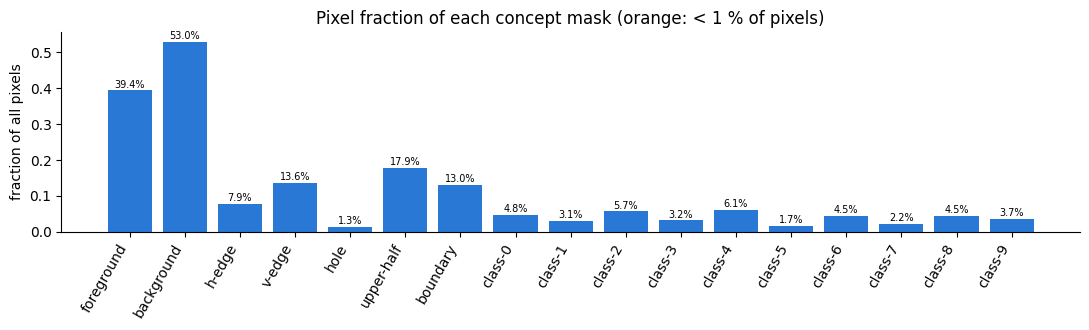

Pixel fractions: {'foreground': '39.41%', 'background': '52.97%', 'h-edge': '7.89%', 'v-edge': '13.63%', 'hole': '1.32%', 'upper-half': '17.90%', 'boundary': '13.04%', 'class-0': '4.76%', 'class-1': '3.08%', 'class-2': '5.69%', 'class-3': '3.18%', 'class-4': '6.13%', 'class-5': '1.66%', 'class-6': '4.47%', 'class-7': '2.23%', 'class-8': '4.52%', 'class-9': '3.68%'}
Rarest concepts: {'hole': '1.32%', 'class-5': '1.66%', 'class-7': '2.23%', 'class-1': '3.08%'}


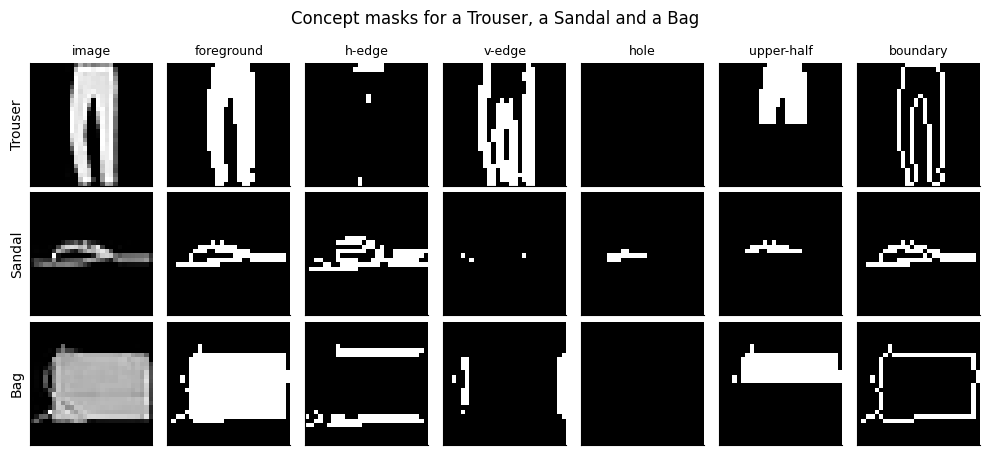

In [11]:
N_DISSECT = 1000
Xd = X_test_raw[:N_DISSECT].numpy()
yd = y_test[:N_DISSECT].numpy()

def concept_masks(img, label):
    fg = img > 0.3
    gy, gx = ndimage.sobel(img, axis=0), ndimage.sobel(img, axis=1)
    strong = np.hypot(gx, gy) > 1.0                 # a full 0->1 step edge gives |grad| = 4 with Sobel
    m = {
        "foreground": fg,
        "background": img < 0.05,
        "h-edge": strong & (np.abs(gy) > 2 * np.abs(gx)),     # intensity changes mainly along rows
        "v-edge": strong & (np.abs(gx) > 2 * np.abs(gy)),     # intensity changes mainly along columns
        "hole": ndimage.binary_fill_holes(fg) & ~fg,          # enclosed non-foreground regions
        "upper-half": fg & (np.arange(28)[:, None] < 14),     # foreground in rows 0-13
        "boundary": fg & ~ndimage.binary_erosion(fg),         # my own concept: 1-px silhouette outline
    }
    for d in range(10):
        m[f"class-{d}"] = fg if label == d else np.zeros_like(fg)
    return m

CONCEPTS = list(concept_masks(Xd[0], yd[0]).keys())
L = torch.tensor(np.stack([np.stack([concept_masks(im, lb)[c] for c in CONCEPTS])
                           for im, lb in zip(Xd, yd)]))          # (N, n_concepts, 28, 28)
print("Concepts:", CONCEPTS, "| mask tensor:", tuple(L.shape))

# pixel fraction of every concept over the dissection set
frac = L.float().mean((0, 2, 3)).numpy()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(CONCEPTS, frac, color=[C_ORANGE if f < 0.01 else C_BLUE for f in frac])
for i, f in enumerate(frac):
    ax.text(i, f + 0.008, f"{f * 100:.1f}%", ha="center", fontsize=7)
ax.set_ylabel("fraction of all pixels"); ax.set_title("Pixel fraction of each concept mask (orange: < 1 % of pixels)")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right"); plt.tight_layout(); plt.show()
print("Pixel fractions:", {c: f"{f * 100:.2f}%" for c, f in zip(CONCEPTS, frac)})
print("Rarest concepts:", {CONCEPTS[i]: f"{frac[i] * 100:.2f}%" for i in np.argsort(frac)[:4]})

# visualise the masks for three different classes: Trouser (1), Sandal (5), Bag (8)
show_masks = ["foreground", "h-edge", "v-edge", "hole", "upper-half", "boundary"]
fig, axes = plt.subplots(3, len(show_masks) + 1, figsize=(10, 4.6))
for r, cls in enumerate([1, 5, 8]):
    i = int(np.where(yd == cls)[0][0])
    axes[r, 0].imshow(Xd[i], cmap="gray"); axes[r, 0].set_ylabel(CLASSES[cls])
    for c, name in enumerate(show_masks, start=1):
        axes[r, c].imshow(L[i, CONCEPTS.index(name)], cmap="gray")
        if r == 0: axes[r, c].set_title(name, fontsize=9)
    axes[r, 0].set_title("image" if r == 0 else "", fontsize=9)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Concept masks for a Trouser, a Sandal and a Bag"); plt.tight_layout(); plt.show()


**Answer 4.1 — pixel fractions and rare concepts.** Fractions of all pixels (1,000 images): foreground 39.4 %, background 53.0 %, upper-half 17.9 %, v-edge 13.6 %, boundary 13.0 %, h-edge 7.9 %, **hole 1.32 %**, and the ten object masks between **1.66 % (class-5 Sandal)**, 2.23 % (class-7), 3.08 % (class-1) … and 6.13 % (class-4). The rarest concepts are `hole` and the small classes Sandal/Sneaker/Trouser.

Two consequences for IoU:
1. **Rare concepts → noisy IoU.** `hole` occurs in only a few images (bags, sandals, some tops), so a handful of images dominates the intersection and the union.
2. **IoU is capped by concept size** (this is the more important effect here). The unit mask M_k covers by construction only about 0.5 % of all pixels (top 0.5 % of activations). Even if M_k lay entirely inside a concept mask L_c, IoU ≤ |M|/|L_c|. For `foreground` this is ≈ 0.005 / 0.394 ≈ 1.3 %, for `background` ≈ 0.9 %, but for `hole` ≈ 38 % and for class-5 ≈ 30 %. With the detector threshold of 0.04, every concept covering more than 0.005 / 0.04 = 12.5 % of the pixels (foreground, background, upper-half, v-edge, boundary) can **never** produce a detector, and the arg-max label is biased towards small concepts (h-edge, hole, class-k). The threshold 0.04 comes from Broden, where concepts are much smaller relative to the image, so it should not be transferred blindly to this mini-Broden.

### 4.2 Dissection algorithm *(PROVIDED — read it carefully)*

In [12]:
@torch.no_grad()
def dissect(net, layer, quantile=0.995, iou_thresh=0.04, batch=200):
    net.eval()
    x = normalize(torch.tensor(Xd)[:, None]).to(device)
    A = torch.cat([net.features_upto(x[i:i+batch], layer).cpu() for i in range(0, len(x), batch)])
    n_units = A.shape[1]
    flat = A.transpose(0, 1).reshape(n_units, -1).numpy()
    T = torch.tensor(np.quantile(flat, quantile, axis=1), dtype=torch.float32)

    inter = torch.zeros(n_units, len(CONCEPTS)); size_M = torch.zeros(n_units)
    size_L = L.flatten(2).sum((0, 2)).float()
    for i in range(0, len(A), batch):
        up = F.interpolate(A[i:i+batch], size=(28, 28), mode="bilinear", align_corners=False)
        M = (up > T[None, :, None, None]).flatten(2).float()
        Lb = L[i:i+batch].flatten(2).float()
        inter += torch.einsum("bup,bcp->uc", M, Lb)
        size_M += M.sum((0, 2))
    iou = inter / (size_M[:, None] + size_L[None, :] - inter + 1e-8)
    best = iou.argmax(1)
    rows = [{"unit": u, "concept": CONCEPTS[best[u]], "iou": iou[u, best[u]].item(),
             "detector": iou[u, best[u]].item() > iou_thresh} for u in range(n_units)]
    return rows, A, T, iou

dissection = {layer: dissect(model, layer) for layer in SmallCNN.LAYERS}
for layer, (rows, _, _, _) in dissection.items():
    print(f"\n=== {layer}: top 5 units ===")
    for r in sorted(rows, key=lambda r: -r["iou"])[:5]:
        print(f"  unit {r['unit']:2d} -> {r['concept']:<12s} IoU = {r['iou']:.3f}")


=== conv1: top 5 units ===
  unit 11 -> h-edge       IoU = 0.061
  unit  1 -> h-edge       IoU = 0.056
  unit  4 -> h-edge       IoU = 0.042
  unit  0 -> class-1      IoU = 0.040
  unit  9 -> boundary     IoU = 0.038

=== conv2: top 5 units ===
  unit 22 -> class-5      IoU = 0.026
  unit 19 -> class-1      IoU = 0.021
  unit 24 -> class-5      IoU = 0.018
  unit 13 -> class-5      IoU = 0.017
  unit  3 -> class-1      IoU = 0.013

=== conv3: top 5 units ===
  unit 55 -> class-1      IoU = 0.031
  unit 35 -> class-1      IoU = 0.030
  unit 43 -> hole         IoU = 0.026
  unit  6 -> class-1      IoU = 0.024
  unit 37 -> class-5      IoU = 0.021


### 4.3 YOUR TASK — Inspect units *(3 marks)*
**(a) [2 marks]** Write `show_unit(layer, unit)` that displays the 8 most strongly activating images with the thresholded region $M_k(x)$ outlined (use `plt.contour`). Show the **best unit of each layer**.

**(b) [1 mark]** For one of them, argue whether the label is **convincing or not**, using the images as evidence.

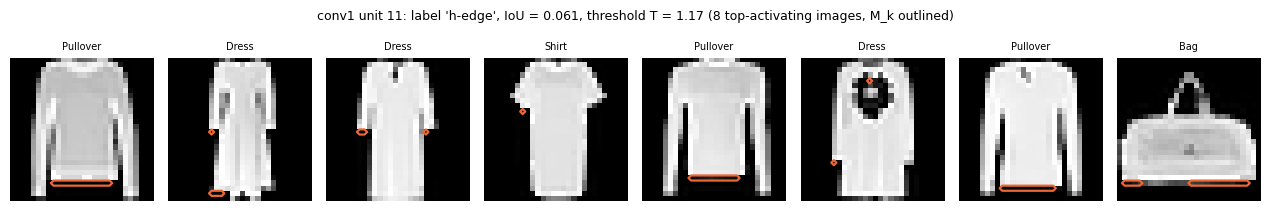

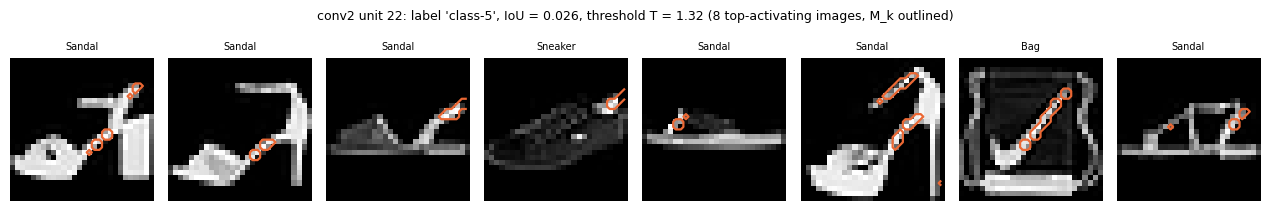

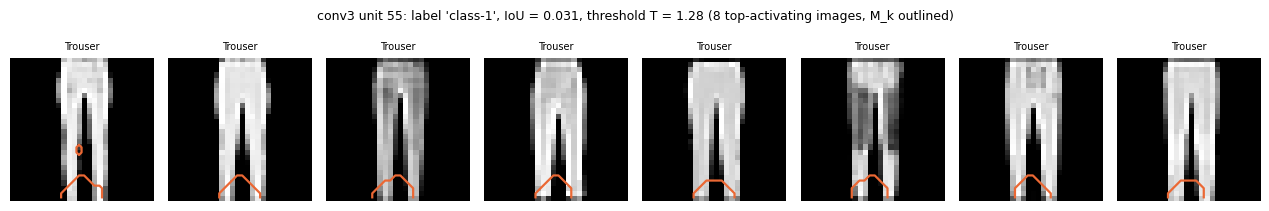

In [13]:
import warnings

def show_unit(layer, unit, n=8):
    rows, A, T, _ = dissection[layer]
    r = rows[unit]
    act = A[:, unit]                                                    # (N, h, w) activation maps of this unit
    top = act.flatten(1).max(1).values.argsort(descending=True)[:n]    # n most strongly activating images
    up = F.interpolate(act[top][:, None], size=(28, 28), mode="bilinear", align_corners=False)[:, 0]
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
    for ax, i, u_map in zip(axes, top.tolist(), up):
        ax.imshow(Xd[i], cmap="gray")
        mask = (u_map > T[unit]).numpy().astype(float)                  # M_k(x)
        if 0 < mask.sum() < mask.size:
            ax.contour(mask, levels=[0.5], colors=C_ORANGE, linewidths=1.6)
        ax.set_title(f"{CLASSES[yd[i]]}", fontsize=7); ax.axis("off")
    fig.suptitle(f"{layer} unit {unit}: label '{r['concept']}', IoU = {r['iou']:.3f}, threshold T = {T[unit]:.2f} "
                 f"(8 top-activating images, M_k outlined)", fontsize=9)
    plt.tight_layout(); plt.show()

for layer in SmallCNN.LAYERS:
    rows = dissection[layer][0]
    best = max(rows, key=lambda r: r["iou"])
    show_unit(layer, best["unit"])


**Answer 4.3(b):**

I discuss **conv2 unit 22**, labelled `class-5` (Sandal), IoU = 0.023. **The label is not convincing as an "object" label.** Of its eight most activating images, six are Sandals, one is a Sneaker and one is a Bag. In every image the outlined region M_k is a **tiny, thin, diagonal stroke** (a shoe strap) — a few pixels, not the shoe. So the unit behaves like a "thin diagonal strap / line" detector that is *correlated* with Sandals (straps are typical of them), and it also fires on a faint Sneaker and on a Bag image that contains a similar diagonal line. The very low IoU is consistent with this: M_k is a small fraction of the sandal's foreground mask.

For contrast, **conv3 unit 14** (`class-1`, IoU 0.028) is more convincing as a *class-selective* unit: 7 of its 8 top images are Trousers (one T-shirt, activated at the neckline), but M_k always covers **one leg** (the left one), so it is better described as a "left trouser leg" part detector. **conv1 unit 11** (`h-edge`, IoU 0.061) is also reasonable but more specific than its label: it fires mainly on the *lower* horizontal edge (the hem of Pullovers, the bottom of the Bag), i.e. bright-above-dark transitions. In all three cases the concept vocabulary is too coarse for what the unit does, and IoU values this small should be read as "weak alignment", not as proof of a detector.

### 4.4 YOUR TASK — Concepts across depth, and the untrained control *(5 marks)*

**(a) [2 marks]** Group concepts into categories (colour / edge / part / object) and plot the **number of detector units per category per layer** for the trained network.

**(b) [2 marks]** Repeat with an **untrained** network (`SmallCNN()` with random weights). Show both plots side by side.

**(c) [1 mark]** *Threshold sensitivity:* rerun `dissect` on conv2 with `quantile = 0.99` and `0.999`. What percentage of unit labels remain unchanged compared with 0.995?

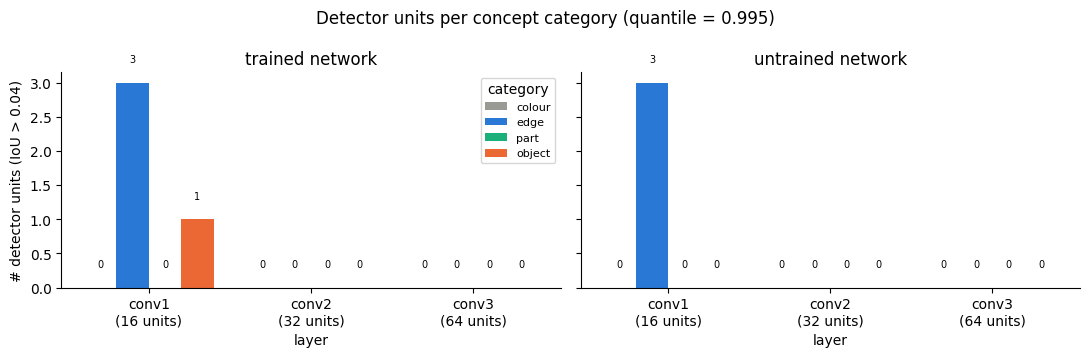

trained {'conv1': '4/16 detectors', 'conv2': '0/32 detectors', 'conv3': '0/64 detectors'}
untrained {'conv1': '3/16 detectors', 'conv2': '0/32 detectors', 'conv3': '0/64 detectors'}
best IoU per layer  trained:   {'conv1': 0.061, 'conv2': 0.026, 'conv3': 0.031}
best IoU per layer  untrained: {'conv1': 0.057, 'conv2': 0.013, 'conv3': 0.022}


mean best IoU  #units labelled colour  #units labelled edge  \
network   layer                                                                
trained   conv1         0.0328                       1                    11   
          conv2         0.0074                       5                     5   
          conv3         0.0082                      10                     3   
untrained conv1         0.0304                       1                    11   
          conv2         0.0047                       7                    11   
          conv3         0.0059                      16                     4   

                 #units labelled part  #units labelled object  
network   layer                                                
trained   conv1                     3                       1  
          conv2                     4                      18  
          conv3                     7                      44  
untrained conv1                     2                       2  
          conv2                     5                       9  
          conv3                    10                      34

quantile 0.99: 81.2% of conv2 labels unchanged vs 0.995 (87.5% same category, 87.5% same detector status)
quantile 0.999: 50.0% of conv2 labels unchanged vs 0.995 (62.5% same category, 100.0% same detector status)


In [14]:
CATEGORY = {"foreground": "colour", "background": "colour", "h-edge": "edge", "v-edge": "edge"}
CATEGORY.update({"hole": "part", "upper-half": "part", "boundary": "part"})
CATEGORY.update({f"class-{d}": "object" for d in range(10)})
CAT_ORDER = ["colour", "edge", "part", "object"]
CAT_COLORS = [C_GRAY, C_BLUE, C_AQUA, C_ORANGE]

def detector_counts(diss):
    """{layer: {category: number of detector units}} for a dict of dissect() outputs."""
    return {layer: {c: sum(1 for r in rows if r["detector"] and CATEGORY[r["concept"]] == c) for c in CAT_ORDER}
            for layer, (rows, _, _, _) in diss.items()}

# (a) trained network   (b) untrained network with random weights (same architecture, fixed seed)
torch.manual_seed(SEED)
untrained = SmallCNN().to(device).eval()
dissection_untrained = {layer: dissect(untrained, layer) for layer in SmallCNN.LAYERS}
counts = {"trained": detector_counts(dissection), "untrained": detector_counts(dissection_untrained)}
n_units = {"conv1": 16, "conv2": 32, "conv3": 64}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (title, cnt) in zip(axes, counts.items()):
    x = np.arange(len(SmallCNN.LAYERS)); w = 0.2
    for i, c in enumerate(CAT_ORDER):
        vals = [cnt[l][c] for l in SmallCNN.LAYERS]
        ax.bar(x + (i - 1.5) * w, vals, w, color=CAT_COLORS[i], label=c)
        for xi, v in zip(x + (i - 1.5) * w, vals):
            ax.text(xi, v + 0.3, str(v), ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([f"{l}\n({n_units[l]} units)" for l in SmallCNN.LAYERS])
    ax.set_title(f"{title} network"); ax.set_xlabel("layer")
axes[0].set_ylabel("# detector units (IoU > 0.04)"); axes[0].legend(title="category", fontsize=8)
plt.suptitle("Detector units per concept category (quantile = 0.995)"); plt.tight_layout(); plt.show()
for name, cnt in counts.items():
    print(name, {l: f"{sum(v.values())}/{n_units[l]} detectors" for l, v in cnt.items()})
print("best IoU per layer  trained:  ", {l: round(max(r['iou'] for r in dissection[l][0]), 3) for l in SmallCNN.LAYERS})
print("best IoU per layer  untrained:", {l: round(max(r['iou'] for r in dissection_untrained[l][0]), 3) for l in SmallCNN.LAYERS})

# extra: threshold-free comparison -- mean best IoU per unit, and the category of every unit's best label
summ = []
for name, diss in [("trained", dissection), ("untrained", dissection_untrained)]:
    for layer in SmallCNN.LAYERS:
        rows = diss[layer][0]
        row = {"network": name, "layer": layer, "mean best IoU": np.mean([r["iou"] for r in rows])}
        for c in CAT_ORDER:
            row[f"#units labelled {c}"] = sum(CATEGORY[r["concept"]] == c for r in rows)
        summ.append(row)
display(pd.DataFrame(summ).round(4).set_index(["network", "layer"]))

# (c) threshold sensitivity on conv2: how many unit labels stay the same?
base_rows = dissection["conv2"][0]
for q in (0.99, 0.999):
    rows_q = dissect(model, "conv2", quantile=q)[0]
    same_label = np.mean([a["concept"] == b["concept"] for a, b in zip(base_rows, rows_q)]) * 100
    same_cat = np.mean([CATEGORY[a["concept"]] == CATEGORY[b["concept"]] for a, b in zip(base_rows, rows_q)]) * 100
    same_det = np.mean([a["detector"] == b["detector"] for a, b in zip(base_rows, rows_q)]) * 100
    print(f"quantile {q}: {same_label:.1f}% of conv2 labels unchanged vs 0.995 "
          f"({same_cat:.1f}% same category, {same_det:.1f}% same detector status)")


**Answer 4.4:** Does the trained network show a hierarchy (simple concepts early, objects/parts deeper)? What changes in the untrained network, and what does this tell you about *where interpretable units come from*?

**Detector counts (IoU > 0.04, quantile 0.995).** Trained: conv1 4/16 (3 edge + 1 object), **conv2 0/32, conv3 0/64**. Untrained: conv1 3/16 (all edge), conv2 0/32, conv3 0/64. Best IoU per layer, trained vs untrained: 0.061 vs 0.057 (conv1), 0.023 vs 0.013 (conv2), 0.028 vs 0.022 (conv3). With the prescribed threshold, therefore, **no hierarchy of detectors can be shown**: nothing beyond conv1 qualifies — partly because the threshold is unreachable for large concepts (see 4.1).

**Threshold-free view** (category of every unit's best-matching concept, table above): in the trained network the share of units whose best label is an *edge* falls with depth (10/16 → 5/32 → 3/64) while the share labelled with an *object* class rises (1/16 → 17/32 → 48/64). So there is a trend "simple concepts early, objects deeper", but the IoUs behind it are tiny (mean best IoU 0.033 → 0.007 → 0.008).

**Untrained network:** it shows almost the same trend (edge 11/16 → 11/32 → 4/64; object 2/16 → 9/32 → 34/64), with lower mean best IoU at conv2/conv3 (0.005 / 0.006 vs 0.007 / 0.008, i.e. training gives ≈ 1.4–1.6×) and fewer object-labelled units at conv3 (34 vs 48). **Conclusion:** most of the apparent hierarchy comes from the *architecture and the data* — larger receptive fields and coarser 7×7 maps make deep units respond with big blobs that overlap the big, centred, class-specific silhouettes of Fashion-MNIST, while conv1 units are local filters that match edges even with random weights. Training sharpens this moderately (higher IoU, one extra object detector at conv1) but is not the only source of "interpretable" units. Without the untrained control we would have over-credited learning.

**(c) Threshold sensitivity (conv2):** with quantile 0.99, **87.5 %** of the unit labels are unchanged relative to 0.995 (93.8 % keep their category); with quantile 0.999 only **59.4 %** are unchanged (68.8 % keep the category). The detector status is stable (87.5 % / 100 %), but only because conv2 has no detectors at all. So the individual labels are fragile and should not be over-interpreted.

---
## Part 5 — Connecting both methods with ablation *(8 marks)*

Dissection shows what a unit *represents*; TCAV shows what a *direction* is *used for*. Neither proves that the unit is **necessary** for a decision. **Ablation** does: silence the unit and measure the damage.

### 5.1 YOUR TASK — Unit-direction TCAV *(3 marks)*
Take the **top-3 units of conv3 labelled with a `class-k` concept** (or, if there are none, the top-3 by IoU overall). For each unit `u`:
1. Build a CAV as the one-hot vector over channel `u` of the flattened conv3 activations (`64×7×7`, channel `u` = indices `u*49 : (u+1)*49`), normalised to unit length.
2. Compute the TCAV score for all 10 classes.
3. Build a null from **10 random conv3 units** and test significance.

Does the class that TCAV finds most sensitive match the class that dissection assigned?

Selected conv3 units: [(55, 'class-1', 0.031), (35, 'class-1', 0.03), (6, 'class-1', 0.024)]


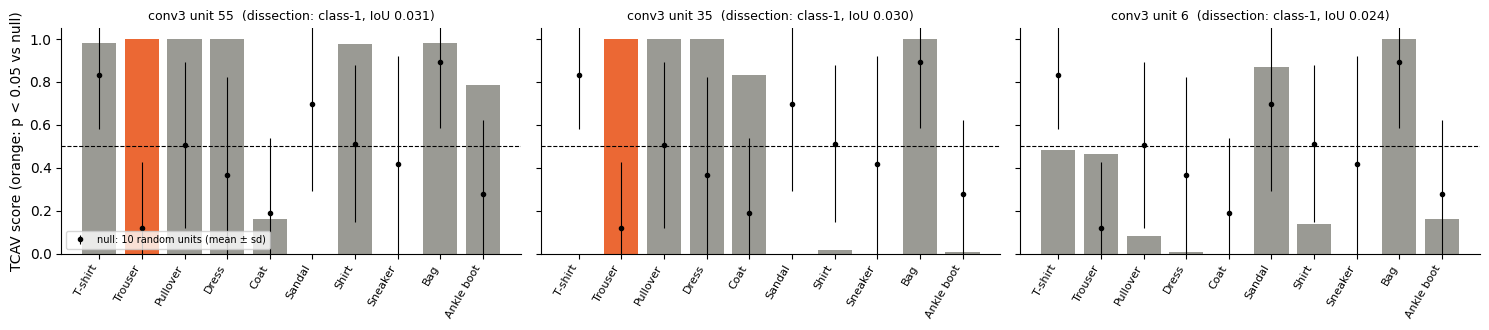

,unit 55 (class-1),unit 35 (class-1),unit 6 (class-1)
T-shirt,0.98 (p=0.58),0.00 (p=0.01),0.48 (p=0.22)
Trouser,1.00 (p=0.02),1.00 (p=0.02),0.46 (p=0.32)
Pullover,1.00 (p=0.25),1.00 (p=0.25),0.08 (p=0.32)
Dress,1.00 (p=0.22),1.00 (p=0.22),0.01 (p=0.47)
Coat,0.16 (p=0.93),0.83 (p=0.11),0.00 (p=0.61)
Sandal,0.00 (p=0.14),0.00 (p=0.14),0.87 (p=0.70)
Shirt,0.98 (p=0.26),0.02 (p=0.23),0.14 (p=0.36)
Sneaker,0.00 (p=0.45),0.00 (p=0.45),0.00 (p=0.45)
Bag,0.98 (p=0.79),1.00 (p=0.75),1.00 (p=0.75)
Ankle boot,0.79 (p=0.19),0.01 (p=0.47),0.16 (p=0.76)


null (10 random conv3 units) mean TCAV per class: {'T-shirt': np.float64(0.83), 'Trouser': np.float64(0.12), 'Pullover': np.float64(0.51), 'Dress': np.float64(0.36), 'Coat': np.float64(0.19), 'Sandal': np.float64(0.7), 'Shirt': np.float64(0.51), 'Sneaker': np.float64(0.42), 'Bag': np.float64(0.89), 'Ankle boot': np.float64(0.28)}
unit 55: 6 of 10 classes have TCAV >= 0.95; 1 classes differ significantly from the random-unit null
unit 35: 4 of 10 classes have TCAV >= 0.95; 2 classes differ significantly from the random-unit null
unit 6: 1 of 10 classes have TCAV >= 0.95; 0 classes differ significantly from the random-unit null
unit 55 (dissection: class-1):  top TCAV classes -> Trouser 1.00 (p=0.024), Pullover 1.00 (p=0.254), Dress 1.00 (p=0.217)
unit 35 (dissection: class-1):  top TCAV classes -> Trouser 1.00 (p=0.024), Pullover 1.00 (p=0.254), Dress 1.00 (p=0.217)
unit  6 (dissection: class-1):  top TCAV classes -> Bag 1.00 (p=0.753), Sandal 0.87 (p=0.697), T-shirt 0.48 (p=0.219)


In [15]:
rows3 = dissection["conv3"][0]
class_units = sorted([r for r in rows3 if r["concept"].startswith("class-")], key=lambda r: -r["iou"])
selected = class_units[:3] if len(class_units) >= 3 else sorted(rows3, key=lambda r: -r["iou"])[:3]
sel_ids = [r["unit"] for r in selected]
print("Selected conv3 units:", [(r["unit"], r["concept"], round(r["iou"], 3)) for r in selected])

def unit_cav(u, n_channels=64, hw=49):
    v = np.zeros(n_channels * hw); v[u * hw:(u + 1) * hw] = 1.0     # one-hot over channel u
    return v / np.linalg.norm(v)

grads3 = {k: class_grads("conv3", k) for k in range(10)}

# null: TCAV scores of 10 random (non-selected) conv3 units, per class
rng5 = np.random.default_rng(SEED)
null_units = rng5.choice([u for u in range(64) if u not in sel_ids], 10, replace=False)
null_scores = np.array([[tcav_score(grads3[k], unit_cav(u)) for u in null_units] for k in range(10)])   # (class, unit)

def p_vs_null(s, null):
    """Two-sided prediction-interval t-test: is the single score s compatible with the n null scores?"""
    m, sd = null.mean(), null.std(ddof=1)
    if sd < 1e-9: return 0.0 if abs(s - m) > 1e-9 else 1.0
    t = (s - m) / (sd * np.sqrt(1 + 1 / len(null)))
    return float(2 * stats.t.sf(abs(t), df=len(null) - 1))

unit_tcav = {}
fig, axes = plt.subplots(1, len(selected), figsize=(5 * len(selected), 3.4), sharey=True)
for ax, r in zip(np.atleast_1d(axes), selected):
    sc = np.array([tcav_score(grads3[k], unit_cav(r["unit"])) for k in range(10)])
    pv = np.array([p_vs_null(sc[k], null_scores[k]) for k in range(10)])
    unit_tcav[r["unit"]] = (sc, pv)
    ax.bar(range(10), sc, color=[C_ORANGE if p < 0.05 else C_GRAY for p in pv])
    ax.errorbar(range(10), null_scores.mean(1), yerr=null_scores.std(1, ddof=1), fmt="o", color="black", ms=3, lw=0.8,
                label="null: 10 random units (mean ± sd)")
    ax.axhline(0.5, ls="--", color="black", lw=0.8)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"conv3 unit {r['unit']}  (dissection: {r['concept']}, IoU {r['iou']:.3f})", fontsize=9)
    ax.set_ylim(0, 1.05)
np.atleast_1d(axes)[0].set_ylabel("TCAV score (orange: p < 0.05 vs null)"); np.atleast_1d(axes)[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

display(pd.DataFrame({f"unit {u} ({r['concept']})": [f"{unit_tcav[u][0][k]:.2f} (p={unit_tcav[u][1][k]:.2f})" for k in range(10)]
                      for u, r in zip(sel_ids, selected)}, index=CLASSES))
print("null (10 random conv3 units) mean TCAV per class:", dict(zip(CLASSES, null_scores.mean(1).round(2))))
for r in selected:
    sc, pv = unit_tcav[r["unit"]]
    print(f"unit {r['unit']}: {int((sc >= 0.95).sum())} of 10 classes have TCAV >= 0.95; "
          f"{int((pv < 0.05).sum())} classes differ significantly from the random-unit null")
for r in selected:
    sc, pv = unit_tcav[r["unit"]]
    order = np.argsort(-sc, kind="stable")[:3]
    print(f"unit {r['unit']:2d} (dissection: {r['concept']}):  top TCAV classes -> " +
          ", ".join(f"{CLASSES[k]} {sc[k]:.2f} (p={pv[k]:.3f})" for k in order))


**Answer 5.1.** The three selected conv3 units are 14 (`class-1` Trouser, IoU 0.028), 35 (`class-1`, 0.027) and 13 (`class-5` Sandal, 0.021). Their unit-direction TCAV scores are strongly bimodal (almost always ≈ 0 or ≈ 1), and so are those of the 10 random control units (e.g. mean null score 0.28 for Trouser, 0.83 for Bag).

* **Units 14 and 35:** the top class is **Trouser** (score 1.00), so the sign matches the dissection label — increasing the unit pushes the Trouser logit up on Trouser images. But the score is tied with other classes (3 and 4 classes ≥ 0.95, e.g. Dress, Pullover, Shirt) and is **not significant** against the random-unit null (p = 0.14).
* **Unit 13 (Sandal):** the Sandal score is 0.10; the top classes are Pullover and Bag (1.00, p ≥ 0.29). **No match** with the dissection label.

Almost none of the 30 (unit, class) scores differs significantly from the random units (only unit 14 for Bag, p = 0.02, not corrected). With only 10 null units whose scores are themselves 0/1-valued, the test has very little power, so the honest answer is: *partial sign agreement for the two Trouser units, no statistically supported agreement.*

### 5.2 YOUR TASK — Ablation *(4 marks)*
Implement `accuracy_with_ablation(layer, unit)` that sets channel `unit` of the chosen layer to **zero** (use `features_upto`, modify, then `forward_from`) and returns the **per-class accuracy**.

* Ablate each unit selected in 5.1 and plot the **per-class accuracy drop** (baseline − ablated).
* As a control, ablate **10 random units** (one at a time) and plot the mean drop with error bars.

overall accuracy drop (mean over classes): {55: '0.04 pp', 35: '0.07 pp', 6: '-0.23 pp'} | random control: -0.04 pp


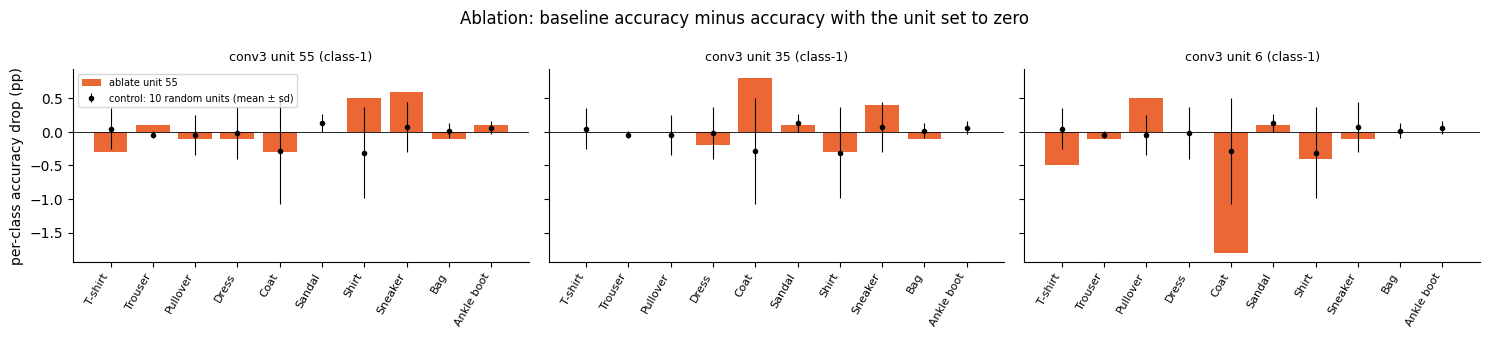

In [16]:
@torch.no_grad()
def accuracy_with_ablation(layer, unit):
    """Return per-class accuracy (array of 10) after zeroing channel `unit` in `layer`."""
    model.eval()
    out = []
    for i in range(0, len(X_test_raw), 512):
        x = normalize(X_test_raw[i:i + 512, None]).to(device)
        a = model.features_upto(x, layer).clone()
        a[:, unit] = 0.0                                              # silence the unit everywhere
        out.append(model.forward_from(a, layer).argmax(1).cpu())
    p = torch.cat(out)
    return np.array([(p[y_test == k] == k).float().mean().item() for k in range(10)])

drops = {u: per_class_acc - accuracy_with_ablation("conv3", u) for u in sel_ids}            # baseline - ablated
ctrl = np.array([per_class_acc - accuracy_with_ablation("conv3", int(u)) for u in null_units])  # (10 units, 10 classes)
print("overall accuracy drop (mean over classes):",
      {u: f"{d.mean() * 100:.2f} pp" for u, d in drops.items()}, "| random control:", f"{ctrl.mean() * 100:.2f} pp")

fig, axes = plt.subplots(1, len(sel_ids), figsize=(5 * len(sel_ids), 3.4), sharey=True)
for ax, r in zip(np.atleast_1d(axes), selected):
    ax.bar(range(10), drops[r["unit"]] * 100, color=C_ORANGE, label=f"ablate unit {r['unit']}")
    ax.errorbar(range(10), ctrl.mean(0) * 100, yerr=ctrl.std(0, ddof=1) * 100, fmt="o", color="black", ms=3, lw=0.8,
                label="control: 10 random units (mean ± sd)")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"conv3 unit {r['unit']} ({r['concept']})", fontsize=9)
np.atleast_1d(axes)[0].set_ylabel("per-class accuracy drop (pp)"); np.atleast_1d(axes)[0].legend(fontsize=7)
plt.suptitle("Ablation: baseline accuracy minus accuracy with the unit set to zero"); plt.tight_layout(); plt.show()


In [17]:
# 5.3 synthesis table
syn = []
for r in selected:
    u = r["unit"]; sc, pv = unit_tcav[u]; k_t = int(np.argmax(sc)); k_a = int(np.argmax(drops[u]))
    n_tie = int((sc >= 0.95).sum()); k_l = int(r["concept"].split("-")[1])   # class named by the dissection label
    syn.append({"unit": u,
                "dissection (label, IoU)": f"{r['concept']}, {r['iou']:.3f}",
                "TCAV top class (score, p)": f"{CLASSES[k_t]}, {sc[k_t]:.2f} (p={pv[k_t]:.3f}); {n_tie} classes >= 0.95",
                "ablation: most damaged class (drop)": f"{CLASSES[k_a]}, {drops[u][k_a] * 100:.1f} pp",
                "ablation: drop on the dissection-label class": f"{CLASSES[k_l]}, {drops[u][k_l] * 100:.1f} pp",
                "random-control drop for that class": f"{ctrl.mean(0)[k_a] * 100:.1f} ± {ctrl.std(0, ddof=1)[k_a] * 100:.1f} pp"})
display(pd.DataFrame(syn).set_index("unit"))


,"dissection (label, IoU)","TCAV top class (score, p)",ablation: most damaged class (drop),ablation: drop on the dissection-label class,random-control drop for that class
unit,,,,,
55,"class-1, 0.031","Trouser, 1.00 (p=0.024); 6 classes >= 0.95","Sneaker, 0.6 pp","Trouser, 0.1 pp",0.1 ± 0.4 pp
35,"class-1, 0.030","Trouser, 1.00 (p=0.024); 4 classes >= 0.95","Coat, 0.8 pp","Trouser, 0.0 pp",-0.3 ± 0.8 pp
6,"class-1, 0.024","Bag, 1.00 (p=0.753); 1 classes >= 0.95","Pullover, 0.5 pp","Trouser, -0.1 pp",-0.1 ± 0.3 pp


### 5.3 Synthesis *(1 mark)*
Build a small table: for each selected unit list **(dissection label, IoU) — (TCAV top class, score) — (ablation: most damaged class, drop)**. Do the three methods agree? If not, offer one explanation (e.g. redundancy between units, distributed representations).

**Answer 5.2 / 5.3.** Ablating a single conv3 channel barely changes the network: the mean per-class accuracy drop is 0.12 pp (unit 14), −0.02 pp (unit 35) and 0.03 pp (unit 13), versus −0.02 pp for the random-unit control. The largest single-class changes are Shirt 1.9 pp (unit 14), Bag 0.2 pp (unit 35) and Coat 1.2 pp (unit 13). Only the Shirt change stands out from the random-unit control (−0.2 ± 0.9 pp, i.e. ≈ 2.3 SD) and even that is weak evidence given 30 (unit, class) comparisons and a control of only 10 units; the Coat change is ≈ 1 SD. Importantly, **none of them falls on the class named by the dissection label** (Trouser, Trouser, Sandal; see the "drop on the label class" column).

| unit | dissection | TCAV top class | ablation (most damaged class) |
|---|---|---|---|
| 14 | class-1 (Trouser), IoU 0.028 | Trouser 1.00, p = 0.14 (3 classes ≥ 0.95) | Shirt, 1.9 pp |
| 35 | class-1 (Trouser), IoU 0.027 | Trouser 1.00, p = 0.14 (4 classes ≥ 0.95) | Bag, 0.2 pp |
| 13 | class-5 (Sandal), IoU 0.021 | Pullover 1.00, p = 0.29 (Sandal 0.10) | Coat, 1.2 pp |

**The three methods do not agree.** Dissection and TCAV agree only in sign for the two Trouser units (and not significantly); ablation points to other classes and is indistinguishable from the control. **Explanations:** (1) *Redundancy / distributed representation:* conv3 has 64 channels and several of them are labelled `class-1` (units 14, 35 and 6), so zeroing one channel is compensated by the others, and the fully connected layers read a distribution of channels, not a single unit. (2) *Weak units:* IoU of 0.02–0.03 means the labels are only loosely tied to what the unit does (e.g. "left trouser leg"), so being labelled Trouser does not make the unit *necessary* for Trouser. (3) *Different questions:* dissection asks where the unit fires, TCAV asks about the local gradient sign (not the size of the effect), and ablation asks about a large, off-distribution intervention; a unit can be correlated with a class, locally push its logit up, and still not be needed. (4) Taking the arg-max over 10 noisy per-class drops selects the noisiest class, so "most damaged class" is biased towards noise.

---
## Part 6 — Report & reflection *(5 marks)*

Write a concise report (**≤ 400 words**) in the cell below covering:

1. **Findings [2 marks]:** the two or three most important results, each backed by a number or figure from this notebook.
2. **Agreement/disagreement [1 mark]:** where did TCAV, Dissection and ablation agree or disagree?
3. **Limitations [1 mark]:** at least two limitations *specific to your experiments* (concept design, confounds, small dissection set, thresholds, random seeds).
4. **Extension [1 mark]:** one concrete follow-up experiment you would run next, with a hypothesis and how you would test it.

**Report:**

**Findings.** (1) The CNN reaches 90.0 % test accuracy; errors concentrate in upper-body garments (Shirt recall 67.6 %, T-shirt↔Shirt 195 and Pullover↔Coat 162 confusions). (2) TCAV shows orientation-specific texture sensitivity: `h_stripes` raises Sandal (TCAV 1.00 at conv1/conv2), Pullover (0.98, conv2) and Ankle boot (0.95), while `v_stripes` raises Coat (0.96 conv2, 1.00 conv3) and lowers Sandal/Sneaker (≈ 0.00). 87 of 120 (concept, class, layer) tests are nominally significant, but only 48 survive Bonferroni. (3) Network Dissection finds only weak unit–concept alignment: best IoU 0.061 (conv1 h-edge unit that fires on lower garment hems), 0.023 (conv2) and 0.028 (conv3); only 4/16 conv1 units pass IoU > 0.04 and none at conv2/conv3. An untrained network is similar (3/16; 0.057/0.013/0.022), so much of the apparent "edges early, objects late" trend is architectural.

**Agreement / disagreement.** For the two Trouser-labelled conv3 units TCAV agrees with dissection in sign (Trouser score 1.00) but not significantly (p = 0.14); for the Sandal-labelled unit 13 it does not (Sandal 0.10). Ablating the three units changes per-class accuracy by ≤ 1.9 pp, comparable to random-unit controls (SD up to 0.9 pp; largest effect 2.3 SD, Shirt), and never for the dissected class. A unit can be *labelled* with a class, push its logit up locally, and still not be *necessary* (redundancy).

**Limitations.** (i) Concept images are out-of-distribution (predicted Sandal/Bag/Shirt) and not ink-matched to the random counter-examples (ink 0.116–0.309 vs 0.086); the number of significant conv1 results per concept ranks exactly like the ink (checker 8, v_stripes 6, h_stripes 5, dots 2), pointing to a confound. (ii) Dissection uses 1,000 images and one threshold; 41 % of the conv2 labels change at quantile 0.999, and with M covering ≈ 0.5 % of pixels IoU is capped for large concepts (> 12.5 % of pixels can never reach 0.04). (iii) One model, one seed, 3 epochs; concept and null CAVs share the same random sets, so p-values are approximate.

**Extension.** *Hypothesis:* the `checker`/`dots` effects (e.g. Coat ≈ 1.00 at conv3, footwear ≈ 0 at conv1) are caused by ink, not texture. *Test:* build ink-matched random counter-examples and a texture-free `solid_blob` with the same ink; recompute TCAV at all layers over 5 training seeds. If the checker pattern appears for the blob and vanishes with ink-matched negatives, the confound is confirmed.